# Simulating a Multi-Agent Conversation

Two character prompts alternate over a shared topic. The notebook defaults to a deterministic responder and performs no network calls. Set `RUN_LIVE_OPENAI=1` and `OPENAI_API_KEY` to use the current Responses API.

In [1]:
import os
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
LIVE_API=os.getenv('RUN_LIVE_OPENAI','0')=='1'
OUTPUT_DIR=Path('generated/openai-603'); OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
characters=[{'name':'James','voice':'measured nobleman','goal':'seek a principled answer'}, {'name':'Blackbeard','voice':'blunt pirate captain','goal':'relate every answer to treasure'}]
topic='What makes a life meaningful?'

## 1. Define an Offline Responder and an Optional Live Adapter

In [2]:
offline_lines={
 'James':['Meaning grows from duties chosen freely.','A legacy is strongest when it improves another life.','Curiosity keeps privilege from becoming a cage.','Then purpose may be the courage to revise our course.'],
 'Blackbeard':['Purpose is the crew that shares the storm.','Treasure matters less than who survives the voyage.','A map is useful only when someone dares to sail.','Then let us spend our days on worthy horizons.']}
def respond(character, previous, turn):
    if not LIVE_API: return offline_lines[character['name']][turn//2]
    from openai import OpenAI
    prompt=f"You are a {character['voice']}. Your goal is to {character['goal']}. Discuss: {topic}. Reply in at most two sentences to: {previous}"
    return OpenAI().responses.create(model=os.getenv('OPENAI_TEXT_MODEL','gpt-4.1-mini'),input=prompt).output_text.strip()

## 2. Alternate Turns and Store a Plain-Text Transcript

In [3]:
turns=[]; previous='Good day. Shall we compare our views?'
for turn in range(8):
    character=characters[turn%2]; response=respond(character,previous,turn); turns.append({'turn':turn+1,'speaker':character['name'],'text':response,'characters':len(response)}); previous=response
transcript=pd.DataFrame(turns); display(transcript[['turn','speaker','text']])
(OUTPUT_DIR/'conversation.txt').write_text('\n'.join(f"{row.speaker}: {row.text}" for row in transcript.itertuples()),encoding='utf-8')

,turn,speaker,text
0,1,James,Meaning grows from duties chosen freely.
1,2,Blackbeard,Purpose is the crew that shares the storm.
2,3,James,A legacy is strongest when it improves another...
3,4,Blackbeard,Treasure matters less than who survives the vo...
4,5,James,Curiosity keeps privilege from becoming a cage.
5,6,Blackbeard,A map is useful only when someone dares to sail.
6,7,James,Then purpose may be the courage to revise our ...
7,8,Blackbeard,Then let us spend our days on worthy horizons.


462

## 3. Inspect Conversation Shape

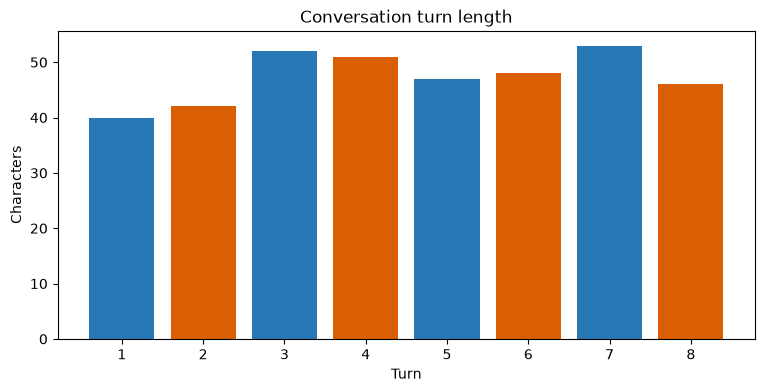

saved: generated\openai-603\conversation-turn-lengths.png


In [4]:
figure,ax=plt.subplots(figsize=(9,4)); colors=transcript['speaker'].map({'James':'#2878b5','Blackbeard':'#d95f02'})
ax.bar(transcript['turn'],transcript['characters'],color=colors); ax.set(title='Conversation turn length',xlabel='Turn',ylabel='Characters'); ax.set_xticks(transcript['turn'])
figure_path=OUTPUT_DIR/'conversation-turn-lengths.png'; figure.savefig(figure_path,dpi=170,bbox_inches='tight'); plt.show(); print('saved:',figure_path)